# run — tuning and running backtests

After setting the run range and strategy parameters, run in order: load data → rolling backtest → compute metrics and save the record → update the report → compare past runs → generate the final portfolio.

| Parameters | Purpose |
| --- | --- |
| A data source, B task constraints | View the fixed configuration |
| C this run | Set `start`, `end`, `step`, `label`, `note` |
| D factor weights, E detailed parameters | Adjust this run's strategy parameters |


In [61]:
%load_ext autoreload
%autoreload 2

from dataclasses import asdict

import pandas as pd

import pf.backtest
import pf.config
import pf.loader
import pf.metrics

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## A, B locked parameters (view only, do not change)

A data source (`DataSpec`) and B task constraints (`TaskSpec`) are shared by all runs, keeping results comparable and the portfolio compliant.

In [62]:
cfg = pf.config.Config()

display(pd.Series(asdict(cfg.data), name="A Data source").to_frame())
display(pd.Series({k: v for k, v in asdict(cfg.task).items() if k != "eval"}, name="B Task constraints").to_frame())
display(pd.Series(asdict(cfg.task.eval), name="B Evaluation setup (EvalSpec)").to_frame())

,A Data source
price_file,prices_raw.csv
price_col,close
revenue_file,revenue_adjusted.csv
benchmark_file,benchmark.csv
benchmark,^GSPC


,B Task constraints
decision_date,2026-10-12
holding_days,39
periods_per_year,252


,B Evaluation setup (EvalSpec)
risk_free,^IRX
index_baselines,"(^GSPC,)"
reference_tickers,"(NVDA,)"
mom_k,3
mom_lookback,252
mom_skip,21
n_random,1000
random_seed,2026
quantiles,"(0.1, 0.9)"


## C This run (required)

`RunSpec` fields have no defaults; leaving one out raises an error immediately.
`start`, `end`, `step`, `label`, `note` must all be filled in explicitly; the label is required (an empty string raises an error), the note may be an empty string.

In [63]:
# Rolling rule: starting from the first trading day ≥ start, take an as_of every step trading days, keeping only those whose following H trading days are all ≤ end
run = pf.config.RunSpec(
    start="2023-01-01",          # backtest start YYYY-MM-DD; data starts 2011-01-03, leave room for ~253 trading days of factor / covariance windows, otherwise no stocks can be selected and it raises
    end="2024-12-31",            # backtest end YYYY-MM-DD; the last day of every holding period is ≤ end (the backtest cutoff chosen here)
    step=cfg.task.holding_days,  # trading days between adjacent as_of dates, ≥ 1; default H: periods joined end to end. When < H periods overlap and there is no portfolio daily return series
    label="val-mad",                    # label (required, empty string raises): inserted into the record file name, briefly describes what this run tried (e.g. "mom_only")
    note="det",                     # note: stored only in the record; may be empty
)

display(pd.Series(asdict(run), name="C This run").to_frame())

,C This run
start,2023-01-01
end,2024-12-31
step,39
label,val-mad
note,det


## D Factor weights (defaults are fine)

Which factors are enabled is determined by the keys in the weights. To turn off a factor, delete it; do not set its weight to 0
(`0 × NaN = NaN`, so a factor with missing values would still make the total score NaN).

In [64]:
# Total score S = Σ σ_k · z_k. To turn off a factor use del cfg.factor_weights["<factor name>"]; do not set it to 0
cfg.factor_weights["momentum"] = 0.4        # σ1
cfg.factor_weights["downside_vol"] = 0.3    # σ2
cfg.factor_weights["revenue_growth"] = 0.4   # σ3
cfg.factor_weights["ret"] = 0.3             # σ4

display(pd.Series(cfg.factor_weights, name="D Factor weights").to_frame())

,D Factor weights
momentum,0.4
downside_vol,0.3
revenue_growth,0.4
ret,0.3


## E Detailed parameters (defaults are fine)

Four cells in pipeline order: factors → standardization → selection → weights.

### E1 Factor parameters

In [65]:
# momentum: P[t−skip] / P[t−lookback] − 1, in trading days; lookback > skip ≥ 0
cfg.factors.momentum.lookback = 189
cfg.factors.momentum.skip = 21

# downside_vol: −√(A · mean(min(r − tau, 0)²)), over the window daily returns up to as_of; A is the B-class periods_per_year
cfg.factors.downside_vol.window = 252
cfg.factors.downside_vol.tau = 0.0

# revenue_growth: (Rev[q] − Rev[q−k]) / Rev[q−k], q is the latest effective fiscal quarter (effective the day after announcement); method ∈ {"yoy", "qoq"}
cfg.factors.revenue_growth.method = "yoy"

# ret uses the config.KNNParams defaults; see knn_test.ipynb for standalone tuning.

factor_view = asdict(cfg.factors)
factor_view.pop("ret")
display(pd.Series(pd.json_normalize(factor_view).to_dict("records")[0], name="E1 Factor params (excl. frozen KNN)", dtype=object).to_frame())
print("ret/KNN: uses the frozen defaults in config.KNNParams; for tuning see notebooks/knn_test.ipynb")


,E1 Factor params (excl. frozen KNN)
momentum.lookback,189
momentum.skip,21
downside_vol.window,252
downside_vol.tau,0.0
revenue_growth.method,yoy


ret/KNN: uses the frozen defaults in config.KNNParams; for tuning see notebooks/knn_test.ipynb


### E2 Standardization

In [66]:
# Shared by all factors: clip at median ± n·MAD (MAD not multiplied by 1.4826), then take a cross-sectional z-score; n > 0
cfg.standardize.n = 5.0

display(pd.Series(asdict(cfg.standardize), name="E2 Standardize").to_frame())

,E2 Standardize
n,5.0


### E3 Stock selection

In [67]:
# Clustering (pf.cluster.hierarchical): adds a cluster column to the score table (A is the largest cluster); selection uses it to cap stocks per cluster
#   distance d = √(2(1 − ρ)), ρ is the correlation of the window daily returns up to as_of (with remove_market, the OLS residuals on mkt)
cfg.cluster.window = 250            # number of daily returns, ≥ 3; 120–250 recommended, below 120 the correlation estimate is too noisy
cfg.cluster.remove_market = True    # True: OLS with intercept on mkt, cluster on residuals (removing common market moves)
cfg.cluster.mkt = "^GSPC"           # market proxy, ∈ {"^GSPC", "^IXIC", "^NDX", "^DJI", "^RUT"} (^VIX cannot be used)
cfg.cluster.method = "complete"     # ∈ {"single", "complete", "average", "ward"}; under complete min_corr has a direct meaning, single suffers from chaining and is not recommended
# Tree cut: exactly one of min_corr and n_clusters is non-None (when using one, set the other to None)
cfg.cluster.min_corr = 0.1          # ∈ [−1, 1]; under complete any two stocks in a cluster have residual correlation ≥ min_corr. Residual correlations are generally low: 0.1 gives ~10 clusters, 0.0 ~7, 0.4 ~21
cfg.cluster.n_clusters = None       # ≥ 1: cut directly into at most this many clusters, independent of the pool's structure

display(pd.Series(asdict(cfg.cluster), name="E3 Clustering", dtype=object).to_frame())

# Selection rule ∈ pf.selection.SELECTORS; currently only "cluster_cap"
cfg.selection.method = "cluster_cap"

# cluster_cap: consider stocks one by one by total score descending; skip if their cluster is full; once min_n are selected, stop when a stock is more than max_gap below the previous selected one; at most max_n stocks
cfg.selection.cluster_cap.max_per_cluster = 2  # max stocks per cluster, ≥ 1; loosen when the cut threshold is loose (large clusters), 1 is enough when tight (small clusters)
cfg.selection.cluster_cap.min_n = 4            # min number of stocks, 1 ≤ min_n ≤ max_n; score gaps are not checked until min_n are selected
cfg.selection.cluster_cap.max_n = 6            # max number of stocks, ≥ 1
cfg.selection.cluster_cap.max_gap = 100.0      # max allowed score gap (total-score units), ≥ 0; 100 means no limit, decide only with backtest support

display(pd.Series(pd.json_normalize(asdict(cfg.selection)).to_dict("records")[0], name="E3 Selection", dtype=object).to_frame())

,E3 Clustering
window,250
remove_market,True
mkt,^GSPC
method,complete
min_corr,0.1
n_clusters,None


,E3 Selection
method,cluster_cap
cluster_cap.max_per_cluster,2
cluster_cap.min_n,4
cluster_cap.max_n,6
cluster_cap.max_gap,100.0


### E4 Weights

In [68]:
# Method ∈ pf.weights.WEIGHTERS; currently only "robust_mvo"
cfg.weights.method = "robust_mvo"

# robust_mvo: max μᵀw − κ·√(wᵀΩw), s.t. Σw + CASH = 1, 0 ≤ CASH ≤ 1, √(wᵀΣw) ≤ max_volatility, lower ≤ w ≤ upper
#   μ = knn's H-day predicted return (predicted_return in the score table; ret must be enabled, NaN μ raises)
#   Σ = H × Ledoit–Wolf(daily returns), Ω = diag(KNN uncertainty²); both on the same H-day basis as μ
# —— Estimation ——
cfg.weights.robust_mvo.lookback = 504  # number of daily returns to estimate Σ, ≥ 2; 126–504 recommended
# —— Preferences ——
cfg.weights.robust_mvo.kappa = 1     # penalty on KNN prediction standard error; 0 is plain MVO

cfg.weights.robust_mvo.max_volatility = 0.15  # portfolio volatility cap over the H-day holding period; 0.10 means at most 10%

# —— Constraints ——
cfg.weights.robust_mvo.lower = 0.00     # no short selling
cfg.weights.robust_mvo.upper = 0.30  # single-stock weight cap; CASH is not subject to it

display(pd.Series(pd.json_normalize(asdict(cfg.weights)).to_dict("records")[0], name="E4 Weights", dtype=object).to_frame())

,E4 Weights
method,robust_mvo
robust_mvo.lookback,504
robust_mvo.kappa,1
robust_mvo.max_volatility,0.15
robust_mvo.lower,0.0
robust_mvo.upper,0.3


## Backtest and save

Below only reads the `cfg` and `run` above; parameters are no longer changed.

/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2023-01-03: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=5
  return predict_return_details(
/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2023-03-01: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=4
  return predict_return_details(
/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2023-04-26: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=2
  return predict_return_details(
/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2023-10-12: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=6
  return predict_return_details(
/Users/tingshuoliang

12 periods: as_of 2023-01-03 → 2024-09-18, last period held until 2024-11-12


/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2024-09-18: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=7
  return predict_return_details(


,end,period_return
as_of,,
2023-01-03,2023-03-01,0.056531
2023-03-01,2023-04-26,0.017095
2023-04-26,2023-06-22,0.081163
2023-06-22,2023-08-17,0.043043
2023-08-17,2023-10-12,0.044238
2023-10-12,2023-12-07,0.056621
2023-12-07,2024-02-05,0.188128
2024-02-05,2024-04-02,0.034824
2024-04-02,2024-05-28,0.066742


ticker,AAPL,ABBV,AMZN,AVGO,BAC,BRK-B,CAT,GE,GOOGL,JPM,...,LMT,MCD,MPC,MSFT,NOW,NVDA,V,WMT,XOM,CASH
as_of,,,,,,,,,,,,,,,,,,,,,
2023-01-03,NaN,0.144,NaN,0.256,NaN,0.300,NaN,NaN,NaN,NaN,...,NaN,NaN,0.300,NaN,NaN,NaN,NaN,NaN,0.0,0.0
2023-03-01,NaN,NaN,NaN,0.300,NaN,NaN,0.000,0.0,NaN,NaN,...,NaN,NaN,0.300,NaN,NaN,NaN,0.3,0.1,NaN,0.0
2023-04-26,NaN,NaN,NaN,0.079,NaN,NaN,0.000,NaN,NaN,NaN,...,0.188,NaN,0.134,NaN,0.300,NaN,0.3,NaN,NaN,0.0
2023-06-22,NaN,NaN,NaN,0.000,NaN,NaN,0.300,NaN,NaN,0.0,...,NaN,0.3,NaN,NaN,NaN,NaN,0.1,NaN,NaN,0.0
2023-08-17,0.3,NaN,NaN,0.137,NaN,NaN,0.263,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.000,0.300,NaN,NaN,NaN,0.0
2023-10-12,NaN,NaN,0.3,0.300,NaN,0.012,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.088,0.300,NaN,NaN,NaN,0.0
2023-12-07,NaN,NaN,NaN,NaN,NaN,0.300,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.022,0.181,0.197,NaN,0.3,NaN,0.0
2024-02-05,0.3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,NaN,NaN,NaN,0.011,0.300,0.208,NaN,NaN,NaN,0.0
2024-04-02,NaN,NaN,NaN,0.143,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,0.000,0.275,0.282,0.3,NaN,NaN,0.0


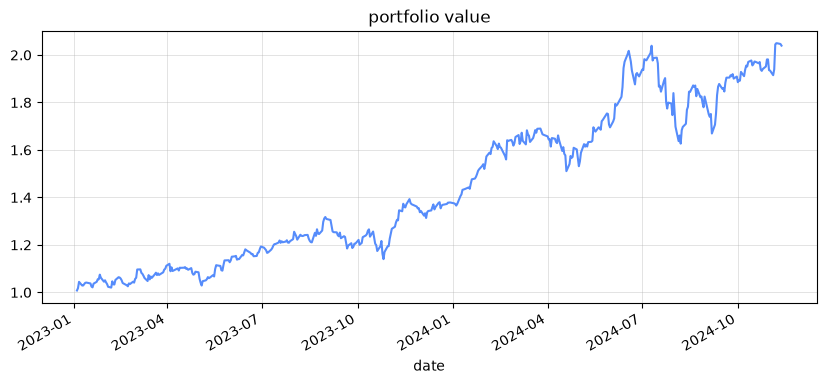

In [69]:
prices = pf.loader.load_prices(cfg.data.price_file, cfg.data.price_col)
fundamentals = pf.loader.load_fundamentals(cfg.data.revenue_file)
benchmarks = pf.loader.load_benchmarks(cfg.data.benchmark_file)  # used by ret (knn) and clustering (remove_market); evaluation also uses index baselines such as ^GSPC and the risk-free rate ^IRX (the backtest raises if ^IRX is missing)

res = pf.backtest.run_backtest(prices, fundamentals, benchmarks, cfg, run)

print(f"{len(res.periods)} periods: as_of {res.periods.index[0].date()} → {res.periods.index[-1].date()}, "
      f"last period held until {res.periods['end'].iloc[-1].date()}")
display(res.periods)
display(res.weights.dropna(axis=1, how="all").round(3))  # entry weights per period, NaN when not selected
if res.returns is not None:  # when step < H periods overlap and there is no portfolio daily return series
    (1 + res.returns).cumprod().plot(title="portfolio value", figsize=(10, 4), grid=True)

## Metrics and saving

Show the per-period detail `period_table` and the summary metrics `evaluate`, and save the parameters, metrics and per-period weights to `outputs/runs/<time>_<label>_<random string>.json`.
`label` and `note` are stored in `meta`; the rolling rule is stored in `run`. NaN is written as JSON `null` and restored on reading.


In [70]:
metrics = pf.metrics.evaluate(res, cfg)
display(pf.metrics.period_table(res, cfg))  # per-period detail, columns are <metric>.<subject>
display(pd.Series(metrics, name="metrics").to_frame())

path = pf.metrics.save_run(cfg, run, res, metrics, pf.config.RUNS_DIR)
print(f"Saved: {path.relative_to(pf.config.PROJECT_ROOT).as_posix()}")

,ret.S,vol.S,sharpe.S,mdd.S,beta.S,alpha.S,n_sel.S,w_cash.S,p_ret.S,p_sharpe.S,...,sharpe.ew_sel,mdd.ew_sel,ret.mom,vol.mom,sharpe.mom,mdd.mom,ret.nvda,vol.nvda,sharpe.nvda,mdd.nvda
as_of,,,,,,,,,,,,,,,,,,,,,
2023-01-03,0.056531,0.176195,1.843696,0.050730,0.656171,0.207571,6,0.000000e+00,39.9,44.3,...,0.307630,0.045615,0.051363,0.300908,1.069894,0.106411,0.585610,0.634861,4.947950,0.100823
2023-03-01,0.017095,0.187874,0.422390,0.044724,0.901669,-0.040197,6,0.000000e+00,36.1,36.3,...,0.550262,0.042908,-0.047015,0.280136,-1.141688,0.115420,0.187594,0.333191,3.360570,0.061649
2023-04-26,0.081163,0.177002,2.649914,0.053502,1.122429,-0.043520,6,0.000000e+00,43.7,48.0,...,2.985267,0.054551,0.198313,0.320988,3.644136,0.067662,0.596120,0.718109,4.477586,0.065718
2023-06-22,0.043043,0.131370,1.739237,0.034616,0.781820,0.278714,6,1.301530e-08,43.9,52.4,...,1.383485,0.046512,0.041922,0.320389,0.820492,0.117407,0.007414,0.397106,0.180840,0.139786
2023-08-17,0.044238,0.213950,1.163848,0.100692,1.462188,0.361120,6,0.000000e+00,97.5,94.4,...,1.758778,0.083455,-0.099579,0.451901,-1.397725,0.215039,0.083079,0.373295,1.419760,0.168939
2023-10-12,0.056621,0.270289,1.254527,0.099118,1.586258,-0.132288,6,0.000000e+00,32.3,19.3,...,1.571000,0.072975,0.429052,0.530935,4.518519,0.099856,-0.007434,0.373813,-0.087025,0.140995
2023-12-07,0.188128,0.135564,7.915725,0.018611,0.971442,0.646879,6,0.000000e+00,97.6,98.7,...,7.394016,0.021569,0.154926,0.535226,1.906497,0.142448,0.487939,0.324656,7.944860,0.050083
2024-02-05,0.034824,0.237493,0.825935,0.046848,1.784906,-0.318854,6,0.000000e+00,19.2,17.4,...,2.039683,0.030506,0.728892,0.980586,4.056389,0.133723,0.290198,0.575838,3.044185,0.086982
2024-04-02,0.066742,0.262917,1.518259,0.090717,1.665703,0.269461,6,0.000000e+00,94.6,85.5,...,1.499472,0.082929,0.086341,0.555171,1.140094,0.236855,0.273320,0.566001,2.950388,0.159089


,metrics
n_periods,1.200000e+01
n_cash_only,0.000000e+00
ret.S.mean,6.209735e-02
ret.S.median,5.038460e-02
ret.S.p10,2.496419e-02
...,...
p_sharpe.ew_sel.mean,5.167500e+01
p_sharpe.ew_sel.median,4.110000e+01
p_sharpe.ew_sel.win,4.166667e-01
n_sel.S.mean,6.000000e+00


Saved: outputs/runs/20261013_171155_val-mad_1cb7.json


In [71]:
# Rerun report.ipynb with the record just saved above (path): replace its RUN_FILE with path.name, execute, and save in place (overwriting report's old outputs)
import re
import nbformat
from nbclient import NotebookClient

report_path = pf.config.PROJECT_ROOT / "notebooks" / "report.ipynb"
nb = nbformat.read(report_path, as_version=4)
pattern = re.compile(r'^RUN_FILE = ".*"$', re.MULTILINE)
hits = [c for c in nb.cells if c.cell_type == "code" and pattern.search(c.source)]
if len(hits) != 1:
    raise ValueError(f'report.ipynb should have exactly one cell containing RUN_FILE = "...", found {len(hits)}')
hits[0].source = pattern.sub(f'RUN_FILE = "{path.name}"', hits[0].source)
NotebookClient(nb, timeout=600, resources={"metadata": {"path": str(report_path.parent)}}).execute()
nbformat.write(nb, report_path)
print(f"Reran with {path.name}: {report_path.relative_to(pf.config.PROJECT_ROOT).as_posix()}")

[IPKernelApp] WARNING | Kernel is running over TCP without encryption. All communication (including code and outputs) is sent in plain text and is susceptible to eavesdropping. Use IPC transport or launch with kernel manager-provisioned CurveZMQ keys to enable transport encryption.


Reran with 20261013_171155_val-mad_1cb7.json: notebooks/report.ipynb


## Comparison of past runs

All records under `outputs/runs/`, one row per run. Full parameters are in the `config.*` columns of `runs` or in each record file.
The summary is generated only in memory and not saved; the label and note columns are `meta.label` and `meta.note`.
Filter by any parameter, e.g. `runs.loc[runs["config.factors.momentum.lookback"] == 252]`.

In [72]:
runs = pf.metrics.load_runs(pf.config.RUNS_DIR)
# List only the parameters whose values differ between runs
varying = [k for k in runs.columns if k.startswith("config.") and runs[k].astype(str).nunique() > 1]
runs[["meta.label", "meta.note", "run.start", "run.end", "run.step", *[k for k in runs.columns if k.startswith("metrics.")], *varying]]

,meta.label,meta.note,run.start,run.end,run.step,metrics.n_periods,metrics.n_cash_only,metrics.ret.S.mean,metrics.ret.S.median,metrics.ret.S.p10,...,config.cluster.window,config.cluster.min_corr,config.selection.cluster_cap.max_per_cluster,config.selection.cluster_cap.max_n,config.selection.cluster_cap.max_gap,config.weights.robust_mvo.lookback,config.weights.robust_mvo.kappa,config.weights.robust_mvo.max_volatility,config.weights.robust_mvo.lower,config.weights.robust_mvo.upper
run,,,,,,,,,,,,,,,,,,,,,
20261003_165223_ltsdemo_2b52,ltsdemo,demo,2021-01-01,2022-09-21,39,11,0,0.032751,0.028380,-0.069541,...,250,0.1,2,6,100.0,252,1.0,0.20,0.0,0.5
20261005_201519_ltsdemo_8f1c,ltsdemo,demo,2021-01-01,2022-09-21,39,11,0,0.032751,0.028380,-0.069541,...,250,0.1,2,6,100.0,252,1.0,0.20,0.0,0.5
20261005_202535_baseline_f8ec,baseline,D/E at config defaults; KNN cfg_008 frozen,2015-01-01,2022-12-31,39,51,0,0.045760,0.034231,-0.063687,...,250,0.1,2,6,100.0,252,0.5,0.10,0.0,0.3
20261005_204634_kappa0_b81d,kappa0,kappa 0.5 -> 0; everything else baseline,2015-01-01,2022-12-31,39,51,0,0.048064,0.040987,-0.065041,...,250,0.1,2,6,100.0,252,0.0,0.10,0.0,0.3
20261005_204956_kappa1_f5f4,kappa1,kappa 0.5 -> 1; everything else baseline,2015-01-01,2022-12-31,39,51,0,0.042843,0.031551,-0.031634,...,250,0.1,2,6,100.0,252,1.0,0.10,0.0,0.3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20261013_161359_dev_cee7,dev,det,2015-10-13,2022-12-31,39,46,0,0.040126,0.036397,-0.042193,...,250,0.1,2,6,100.0,504,1.0,0.15,0.0,0.3
20261013_161524_val_a5bc,val,det,2023-01-01,2024-12-31,39,12,0,0.060267,0.043864,0.024964,...,250,0.1,2,6,100.0,504,1.0,0.15,0.0,0.3
20261013_165441_dev_b615,dev,re,2015-10-13,2022-12-31,39,46,0,0.040126,0.036397,-0.042193,...,250,0.1,2,6,100.0,504,1.0,0.15,0.0,0.3


In [73]:
runs = pf.metrics.load_runs(pf.config.RUNS_DIR)
runs.loc[
    runs["meta.label"].isin(["mom189", "cov126", "cov504"]),
    ["meta.label", "meta.note", "metrics.sharpe.S.median", "metrics.mdd.S.p90"],
]

,meta.label,meta.note,metrics.sharpe.S.median,metrics.mdd.S.p90
run,,,,
20261005_212827_mom189_2826,mom189,momentum.lookback 252 -> 189; n=8; kappa=0.5; ...,1.492680,0.134566
20261006_004805_cov126_519d,cov126,robust_mvo.lookback 252 -> 126; max_per_cluste...,1.492661,0.136983
20261006_165330_cov504_8a92,cov504,robust_mvo.lookback 252 -> 504; max_per_cluste...,1.214755,0.149444


## Final portfolio

Once parameters are settled, make one decision with `decision_date` as as_of, outputting only the portfolio without computing returns.

Only for the final submission: with **USD 1,000,000** of capital and **1 share per lot**, round down; all remaining money goes to CASH.
The table below lists the target weight, integer shares/lots, actual amount and actual position weight. Tuning, backtests and their saved results keep using continuous weights.

In [74]:
from decimal import Decimal, ROUND_FLOOR, localcontext

# For the final submission only; does not modify cfg, model weights or backtest results.
initial_capital = 1_000_000  # USD; fixed at 1 share per lot
final_portfolio = None
final_as_of = pd.Timestamp(cfg.task.decision_date)
if final_as_of in prices.index:
    final_table, target_weights = pf.backtest.decide(
        prices, fundamentals, benchmarks, final_as_of, cfg
    )
    with localcontext() as ctx:
        ctx.prec = 40
        capital = Decimal(str(initial_capital))
        raw = {ticker: Decimal(str(value)) for ticker, value in target_weights.items()}
        tolerance = Decimal('1e-8')
        if not raw or any(not value.is_finite() or value < -tolerance for value in raw.values()):
            raise ValueError('final target weights must be finite and non-negative')
        if abs(sum(raw.values()) - 1) > tolerance:
            raise ValueError('final target weights (including cash) must sum to 1')
        # Only fix tiny solver errors; decimal arithmetic avoids buying one share too few at integer boundaries due to floating-point error.
        raw = {ticker: max(value, Decimal(0)) for ticker, value in raw.items()}
        total = sum(raw.values())
        stock_tickers = [ticker for ticker in raw if ticker != 'CASH']
        final_portfolio = final_table.reindex([*stock_tickers, 'CASH']).copy()
        final_portfolio['price'] = prices.loc[final_as_of].reindex(final_portfolio.index)
        final_portfolio['target_weight'] = [float(raw.get(ticker, 0) / total) for ticker in final_portfolio.index]
        final_portfolio['shares'] = pd.Series(pd.NA, index=final_portfolio.index, dtype='Int64')
        final_portfolio['amount'] = 0.0
        spent = Decimal(0)
        for ticker in stock_tickers:
            price = Decimal(str(final_portfolio.loc[ticker, 'price']))
            if not price.is_finite() or price <= 0:
                raise ValueError(f'entry price of {ticker} is missing or invalid')
            shares = int((capital * raw[ticker] / (total * price)).to_integral_value(rounding=ROUND_FLOOR))
            amount = shares * price
            final_portfolio.loc[ticker, 'shares'] = shares
            final_portfolio.loc[ticker, 'amount'] = float(amount)
            spent += amount
        final_portfolio.loc['CASH', 'amount'] = float(capital - spent)
    final_portfolio['lots'] = final_portfolio['shares']  # 1 share/lot; cash has no shares or lots
    final_portfolio['weight'] = final_portfolio['amount'] / initial_capital
    display(final_portfolio[['price', 'target_weight', 'shares', 'lots', 'amount', 'weight']].rename(columns={
        'price': 'Entry price (USD)', 'target_weight': 'Target weight', 'shares': 'Shares',
        'lots': 'Lots (1 share/lot)', 'amount': 'Position value (USD)', 'weight': 'Actual weight',
    }).style.format({
        'Entry price (USD)': '{:,.2f}', 'Target weight': '{:.4%}', 'Shares': '{:,.0f}',
        'Lots (1 share/lot)': '{:,.0f}', 'Position value (USD)': '{:,.2f}', 'Actual weight': '{:.4%}',
    }, na_rep='—'))
    print(f"Initial capital: ${initial_capital:,.2f}; cash: ${final_portfolio.loc['CASH', 'amount']:,.2f}; "
          f"total actual weight: {final_portfolio['weight'].sum():.6%}")
else:
    print(f"decision_date={final_as_of.date()} has no data yet (prices run to {prices.index[-1].date()})")

/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2026-10-12: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=4
  return predict_return_details(


,Entry price (USD),Target weight,Shares,Lots (1 share/lot),Position value (USD),Actual weight
ticker,,,,,,
MPC,458.81,5.7388%,125,125,"57,351.25",5.7351%
AAOI,100.68,0.0000%,0,0,0.00,0.0000%
NVDA,226.32,4.2612%,188,188,"42,548.16",4.2548%
LLY,"1,182.62",30.0000%,253,253,"299,202.86",29.9203%
AVGO,354.73,30.0000%,845,845,"299,746.86",29.9747%
JPM,334.30,30.0000%,897,897,"299,867.09",29.9867%
CASH,—,0.0000%,—,—,"1,283.78",0.1284%


Initial capital: $1,000,000.00; cash: $1,283.78; total actual weight: 100.000000%


In [75]:
from decimal import Decimal, ROUND_FLOOR, localcontext

# For the final submission only; does not modify cfg, model weights or backtest results.
initial_capital = 1_000_000  # USD; fixed at 1 share per lot
final_portfolio = None
final_as_of = pd.Timestamp(cfg.task.decision_date)
if final_as_of in prices.index:
    final_table, target_weights = pf.backtest.decide(
        prices, fundamentals, benchmarks, final_as_of, cfg
    )
    with localcontext() as ctx:
        ctx.prec = 40
        capital = Decimal(str(initial_capital))
        raw = {ticker: Decimal(str(value)) for ticker, value in target_weights.items()}
        tolerance = Decimal('1e-8')
        if not raw or any(not value.is_finite() or value < -tolerance for value in raw.values()):
            raise ValueError('final target weights must be finite and non-negative')
        if abs(sum(raw.values()) - 1) > tolerance:
            raise ValueError('final target weights (including cash) must sum to 1')
        # Only fix tiny solver errors; decimal arithmetic avoids buying one share too few at integer boundaries due to floating-point error.
        raw = {ticker: max(value, Decimal(0)) for ticker, value in raw.items()}
        total = sum(raw.values())
        stock_tickers = [ticker for ticker in raw if ticker != 'CASH']
        final_portfolio = final_table.reindex([*stock_tickers, 'CASH']).copy()
        final_portfolio['price'] = prices.loc[final_as_of].reindex(final_portfolio.index)
        final_portfolio['target_weight'] = [float(raw.get(ticker, 0) / total) for ticker in final_portfolio.index]
        final_portfolio['shares'] = pd.Series(pd.NA, index=final_portfolio.index, dtype='Int64')
        final_portfolio['amount'] = 0.0
        spent = Decimal(0)
        for ticker in stock_tickers:
            price = Decimal(str(final_portfolio.loc[ticker, 'price']))
            if not price.is_finite() or price <= 0:
                raise ValueError(f'entry price of {ticker} is missing or invalid')
            shares = int((capital * raw[ticker] / (total * price)).to_integral_value(rounding=ROUND_FLOOR))
            amount = shares * price
            final_portfolio.loc[ticker, 'shares'] = shares
            final_portfolio.loc[ticker, 'amount'] = float(amount)
            spent += amount
        final_portfolio.loc['CASH', 'amount'] = float(capital - spent)
    final_portfolio['lots'] = final_portfolio['shares']  # 1 share/lot; cash has no shares or lots
    final_portfolio['weight'] = final_portfolio['amount'] / initial_capital

    # ---------- Output as copyable plain text ----------
    columns = {
        'price': 'Entry price (USD)', 'target_weight': 'Target weight', 'shares': 'Shares',
        'lots': 'Lots (1 share/lot)', 'amount': 'Position value (USD)', 'weight': 'Actual weight',
    }
    formats = {
        'Entry price (USD)': '{:,.2f}', 'Target weight': '{:.4%}', 'Shares': '{:,.0f}',
        'Lots (1 share/lot)': '{:,.0f}', 'Position value (USD)': '{:,.2f}', 'Actual weight': '{:.4%}',
    }
    out = final_portfolio[list(columns)].rename(columns=columns)
    text_table = pd.DataFrame(index=out.index)
    for col, fmt in formats.items():
        text_table[col] = ['—' if pd.isna(v) else fmt.format(v) for v in out[col]]
    text_table.index.name = 'Ticker'

    summary = (f"Initial capital: ${initial_capital:,.2f}; cash: ${final_portfolio.loc['CASH', 'amount']:,.2f}; "
               f"total actual weight: {final_portfolio['weight'].sum():.6%}")

    # 1) Aligned text table, easy to read and copy
    with pd.option_context('display.unicode.east_asian_width', True,
                           'display.max_rows', None, 'display.width', 200):
        print(text_table.to_string())
    print(summary)

    # 2) Tab-separated version, can be pasted directly into Excel / spreadsheet software
    print('\n===== Tab-separated (paste into Excel) =====')
    print(text_table.to_csv(sep='\t'), end='')
    print(summary)
else:
    print(f"decision_date={final_as_of.date()} has no data yet (prices run to {prices.index[-1].date()})")

/Users/tingshuoliang/Downloads/Part1_codes/pf/factors.py:257: UserWarning: as_of=2026-10-12: after time de-duplication, neighbors are fewer than min_neighbors=8; still predicting with the existing window: ONDS=4
  return predict_return_details(


       Entry price (USD) Target weight Shares Lots (1 share/lot) Position value (USD) Actual weight
Ticker                                                                                             
MPC               458.81       5.7388%    125                125            57,351.25       5.7351%
AAOI              100.68       0.0000%      0                  0                 0.00       0.0000%
NVDA              226.32       4.2612%    188                188            42,548.16       4.2548%
LLY             1,182.62      30.0000%    253                253           299,202.86      29.9203%
AVGO              354.73      30.0000%    845                845           299,746.86      29.9747%
JPM               334.30      30.0000%    897                897           299,867.09      29.9867%
CASH                   —       0.0000%      —                  —             1,283.78       0.1284%
Initial capital: $1,000,000.00; cash: $1,283.78; total actual weight: 100.000000%

===== Tab-separat